In [3]:
%matplotlib widget
import importlib
import numpy as np
import scipy as sc
from scipy.special import jv
import os
import matplotlib.pyplot as plt

from scipy.optimize import curve_fit
import mpmath
from mpmath import *
import time
import pandas as pd
import matplotlib as mpl
mpl.rcParams["font.size"] = 22



import data

In [4]:
os.chdir(r'C:\Users\nberr\ENS_Lyon\M2\Stage\Framboises')

df_sheet_all = pd.read_excel('simulations_article.xlsx', sheet_name=None)
Lambda= {}
Energy = {}
Sigma = {}


for key in ['Au_sphere', 'Ag_nanocube', 'Nanocluster'] :
    
    data = df_sheet_all[key].__array__()

    Lambda[key] = np.array(data[:,0])
    Energy[key] = np.array(data[:,1])
    Sigma[key] = np.array(data[:,2])


    #sort everything
    index_sorted = Lambda[key].argsort()

    Lambda[key] = Lambda[key][index_sorted]
    Sigma[key] = Sigma[key][index_sorted]
    Energy[key] = Energy[key][index_sorted]

    #Cut lambda at 800 nm
    idx_sup = np.searchsorted(Lambda[key], 700)
    idx_inf = np.searchsorted(Lambda[key], 350)
    
    Lambda[key] = Lambda[key][idx_inf:idx_sup]
    Sigma[key] = Sigma[key][idx_inf:idx_sup]
    Energy[key] = Energy[key][idx_inf:idx_sup]

   
        
                

## Plot

Single satellite

<>:5: SyntaxWarning: invalid escape sequence '\s'
<>:6: SyntaxWarning: invalid escape sequence '\l'
<>:5: SyntaxWarning: invalid escape sequence '\s'
<>:6: SyntaxWarning: invalid escape sequence '\l'
C:\Users\nberr\AppData\Local\Temp\ipykernel_4488\2543271864.py:5: SyntaxWarning: invalid escape sequence '\s'
  plt.ylabel("$\sigma_{ext}$ ($10^3$ nm2)")
C:\Users\nberr\AppData\Local\Temp\ipykernel_4488\2543271864.py:6: SyntaxWarning: invalid escape sequence '\l'
  plt.xlabel('$\lambda$ (nm)')
C:\Users\nberr\AppData\Local\Temp\ipykernel_4488\2543271864.py:8: RuntimeWarning: divide by zero encountered in divide
  f = lambda x : 1240/(x)


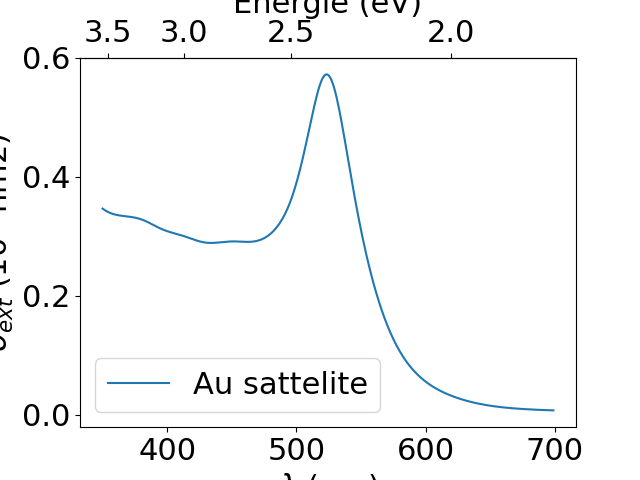

In [5]:
fig, ax = plt.subplots()

plt.plot(Lambda['Au_sphere'], Sigma['Au_sphere'], label = 'Au sattelite')

plt.ylabel("$\sigma_{ext}$ ($10^3$ nm2)")
plt.xlabel('$\lambda$ (nm)')

f = lambda x : 1240/(x)
ax2 = ax.secondary_xaxis("top", functions=(f,f))

ax2.set_xlabel("Energie (eV)")


plt.legend()

os.chdir(r'C:\Users\nberr\ENS_Lyon\M2\Stage\Rapport de stage\Figures\Intro_physique')
# plt.savefig('err.pdf')

Single nanocube

<>:5: SyntaxWarning: invalid escape sequence '\s'
<>:6: SyntaxWarning: invalid escape sequence '\l'
<>:5: SyntaxWarning: invalid escape sequence '\s'
<>:6: SyntaxWarning: invalid escape sequence '\l'
C:\Users\nberr\AppData\Local\Temp\ipykernel_4488\388570309.py:5: SyntaxWarning: invalid escape sequence '\s'
  plt.ylabel("$\sigma_{ext}$ ($10^3$ nm2)")
C:\Users\nberr\AppData\Local\Temp\ipykernel_4488\388570309.py:6: SyntaxWarning: invalid escape sequence '\l'
  plt.xlabel('$\lambda$ (nm)')
C:\Users\nberr\AppData\Local\Temp\ipykernel_4488\388570309.py:8: RuntimeWarning: divide by zero encountered in divide
  f = lambda x : 1240/(x)


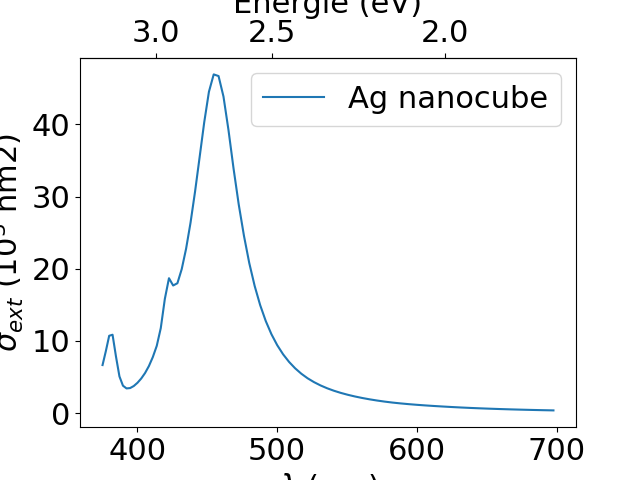

C:\Users\nberr\AppData\Local\Temp\ipykernel_4488\388570309.py:8: RuntimeWarning: divide by zero encountered in divide
  f = lambda x : 1240/(x)


In [ ]:
fig, ax = plt.subplots()

plt.plot(Lambda['Ag_nanocube'], Sigma['Ag_nanocube'], label = 'Ag nanocube')

plt.ylabel("$\sigma_{ext}$ ($10^3$ nm2)")
plt.xlabel('$\lambda$ (nm)')

f = lambda x : 1240/(x)
ax2 = ax.secondary_xaxis("top", functions=(f,f))

ax2.set_xlabel("Energie (eV)")


plt.legend()

os.chdir(r'C:\Users\nberr\ENS_Lyon\M2\Stage\Rapport de stage\Figures\Intro_physique')
# plt.savefig('err.pdf')

Nanocluster with 4 satellites

<>:7: SyntaxWarning: invalid escape sequence '\s'
<>:8: SyntaxWarning: invalid escape sequence '\l'
<>:7: SyntaxWarning: invalid escape sequence '\s'
<>:8: SyntaxWarning: invalid escape sequence '\l'
C:\Users\nberr\AppData\Local\Temp\ipykernel_4488\4241753176.py:7: SyntaxWarning: invalid escape sequence '\s'
  plt.ylabel("$\sigma_{ext}$ ($10^3$ nm$^2$)")
C:\Users\nberr\AppData\Local\Temp\ipykernel_4488\4241753176.py:8: SyntaxWarning: invalid escape sequence '\l'
  plt.xlabel('$\lambda$ (nm)')
C:\Users\nberr\AppData\Local\Temp\ipykernel_4488\4241753176.py:11: RuntimeWarning: divide by zero encountered in divide
  f = lambda x : 1240/(x)


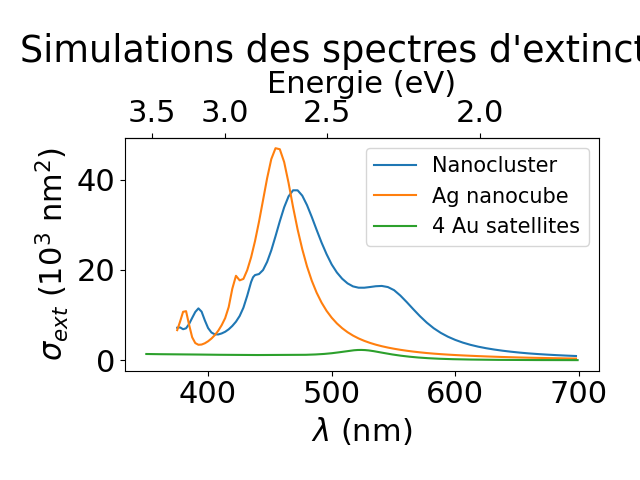

C:\Users\nberr\AppData\Local\Temp\ipykernel_4488\4241753176.py:11: RuntimeWarning: divide by zero encountered in divide
  f = lambda x : 1240/(x)


In [7]:
fig, ax = plt.subplots()

plt.plot(Lambda['Nanocluster'], Sigma['Nanocluster'], label = 'Nanocluster')
plt.plot(Lambda['Ag_nanocube'], Sigma['Ag_nanocube'], label = 'Ag nanocube')
plt.plot(Lambda['Au_sphere'], 4*Sigma['Au_sphere'], label = '4 Au satellites')

plt.ylabel("$\sigma_{ext}$ ($10^3$ nm$^2$)")
plt.xlabel('$\lambda$ (nm)')


f = lambda x : 1240/(x)
ax2 = ax.secondary_xaxis("top", functions=(f,f))

ax2.set_xlabel("Energie (eV)")
plt.title('Simulations des spectres d\'extinction')
plt.tight_layout()
plt.legend(fontsize = 15)

os.chdir(r'C:\Users\nberr\ENS_Lyon\M2\Stage\Rapport de stage\Figures\Diapo')
#plt.savefig('Spectre_nanocluster.pdf', bbox_inches='tight')
plt.show()

In [ ]:
fig, ax = plt.subplots()

plt.plot(Lambda['Nanocluster'], Sigma['Nanocluster'], label = 'Nanocluster')

plt.ylabel("$\sigma_{ext}$ ($10^3$ nm2)")
plt.xlabel('$\lambda$ (nm)')

f = lambda x : 1240/(x)
ax2 = ax.secondary_xaxis("top", functions=(f,f))

ax2.set_xlabel("Energie (eV)")


plt.legend()

os.chdir(r'C:\Users\nberr\ENS_Lyon\M2\Stage\Rapport de stage\Figures\Intro_physique')
# plt.savefig('err.pdf')

C:\Users\nberr\AppData\Local\Temp\ipykernel_4488\2543271864.py:8: RuntimeWarning: divide by zero encountered in divide
  f = lambda x : 1240/(x)


C:\Users\nberr\AppData\Local\Temp\ipykernel_4488\1111274955.py:8: RuntimeWarning: divide by zero encountered in divide
  f = lambda x : 1240/(x)
